# Figures for the paper (Parts 5 and 6)

Reads the CSVs that `validate` writes into `results/` and saves each figure to
`figures/` as both PDF (vector, for LaTeX) and PNG.

Regenerate the data first if needed:

```sh
make part3   # ./search         -> part3_counterexamples.csv
make part5   # ./validate       -> instances.csv, part5_summary.csv, part5_worst.txt
make part6   # ./validate time  -> part6_timing.csv
```

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("results")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# One fixed color per heuristic, used in every figure. Colors are checked for
# colorblind separation; each series also gets its own marker and line style
# so the figures still read in black-and-white print.
HEURISTICS = ["eft", "est", "sd", "fc"]
NAMES = {"eft": "Earliest Finish", "est": "Earliest Start",
         "sd": "Shortest Duration", "fc": "Fewest Conflicts"}
COLORS = {"eft": "#2a78d6", "est": "#eb6834", "sd": "#1baf7a", "fc": "#eda100"}
MARKERS = {"eft": "o", "est": "s", "sd": "^", "fc": "D"}
LINES = {"eft": "-", "est": "--", "sd": "-.", "fc": ":"}
FAMILIES = ["sparse", "dense", "varied", "clustered"]

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
    "lines.linewidth": 1.6, "lines.markersize": 5,
    "pdf.fonttype": 42,  # embed TrueType so the PDF text stays editable
})

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{ext}")
    print(f"saved figures/{name}.pdf and .png")

## Part 3: counterexample timelines

The counterexamples reported for Earliest Start, Shortest Duration and Fewest
Conflicts (the `chosen` rows of `part3_counterexamples.csv`, written by
`make part3`). Each row is one job. Jobs the heuristic picked are filled in its
color, and the optimal solution is marked with a dark outline, as in Figure 4.
Earliest Start and Shortest Duration label jobs A, B, C as in the report table.

saved figures/fig_part3_counterexamples.pdf and .png


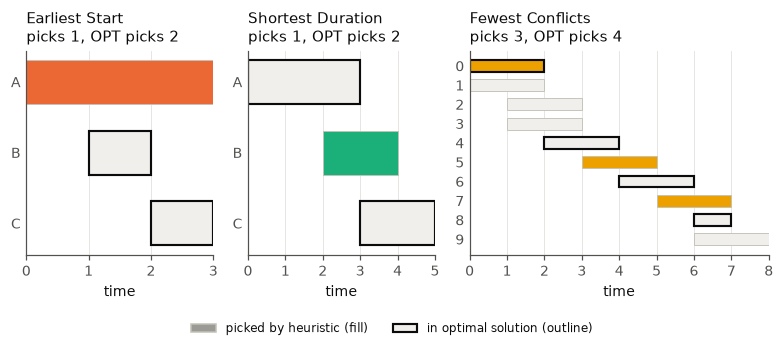

In [2]:
cx = pd.read_csv(RESULTS / "part3_counterexamples.csv")
cx = cx[cx.chosen == 1].set_index("heuristic").loc[["est", "sd", "fc"]]

def ids(cell):
    return {int(x) for x in str(cell).split(";")}

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9),
                         gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, (h, row) in zip(axes, cx.iterrows()):
    jobs = [tuple(map(int, j.split("-"))) for j in row.jobs.split(";")]
    picked, optimal = ids(row.h_sel), ids(row.opt_sel)
    letters = h != "fc"
    for jid, (s, f) in enumerate(jobs):
        ax.barh(jid, f - s, left=s, height=0.62,
                color=COLORS[h] if jid in picked else "#f0efec",
                edgecolor=INK if jid in optimal else "#c3c2b7",
                linewidth=1.4 if jid in optimal else 0.6)
    ax.set_yticks(range(len(jobs)),
                  [chr(ord("A") + j) if letters else str(j) for j in range(len(jobs))])
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    end = max(f for _, f in jobs)
    ax.set_xlim(min(s for s, _ in jobs), end)
    ax.set_xticks(range(min(s for s, _ in jobs), end + 1))
    ax.set_xlabel("time")
    ax.set_title(f"{NAMES[h]}\npicks {row.h_size}, OPT picks {row.opt}", loc="left")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor="#9b9a95", edgecolor="#c3c2b7", label="picked by heuristic (fill)"),
                    Patch(facecolor="#f0efec", edgecolor=INK, linewidth=1.4, label="in optimal solution (outline)")],
           loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
save(fig, "fig_part3_counterexamples")

## Part 5: solution quality, |H(I)| / OPT(I)

In [3]:
inst = pd.read_csv(RESULTS / "instances.csv")
summary5 = pd.read_csv(RESULTS / "part5_summary.csv")
for h in HEURISTICS:
    inst[f"{h}_ratio"] = inst[h] / inst["opt"]

overall = (summary5[summary5.family == "all"].set_index("heuristic").loc[HEURISTICS]
           [["tested", "optimal", "optimal_rate", "avg_ratio", "worst_ratio",
             "worst_instance", "worst_h", "worst_opt"]])
overall.index = [NAMES[h] for h in overall.index]
print(f"{len(inst)} instances, n from {inst.n.min()} to {inst.n.max()}")
overall

800 instances, n from 4 to 18


,tested,optimal,optimal_rate,avg_ratio,worst_ratio,worst_instance,worst_h,worst_opt
Earliest Finish,800,800,1.0000,1.0000,1.0000,0,3,3
Earliest Start,800,536,0.6700,0.8805,0.1667,494,1,6
Shortest Duration,800,769,0.9613,0.9841,0.5000,200,1,2
Fewest Conflicts,800,800,1.0000,1.0000,1.0000,0,3,3


### Figure 1: how often each heuristic is optimal, and how close it gets

Two panels because the measures have different scales.

saved figures/fig1_quality_overall.pdf and .png


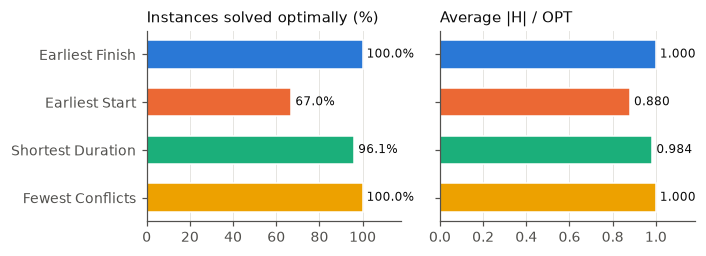

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.4))
y = np.arange(len(HEURISTICS))[::-1]
panels = [("optimal_rate", 100, "Instances solved optimally (%)", "{:.1f}%"),
          ("avg_ratio", 1, "Average |H| / OPT", "{:.3f}")]
for ax, (col, scale, title, fmt) in zip(axes, panels):
    vals = summary5[summary5.family == "all"].set_index("heuristic").loc[HEURISTICS, col] * scale
    ax.barh(y, vals, height=0.6, color=[COLORS[h] for h in HEURISTICS],
            edgecolor="white", linewidth=1)
    for yi, v in zip(y, vals):
        ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=8, color=INK)
    ax.set_yticks(y, [NAMES[h] for h in HEURISTICS])
    ax.set_xlim(0, scale * 1.18)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.tight_layout()
save(fig, "fig1_quality_overall")

### Figure 2: share of optimal instances by family

A single blue scale, from light (low) to dark (high). Each cell prints its
value, so the color only supports the numbers.

saved figures/fig2_optimal_by_family.pdf and .png


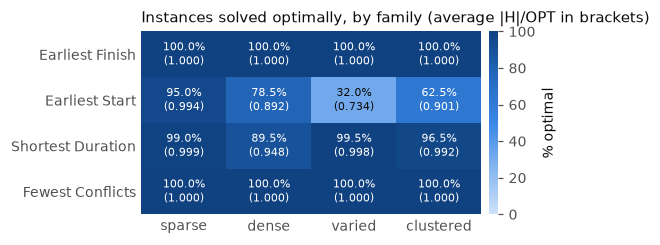

In [5]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
fam = summary5[summary5.family != "all"]
rate = fam.pivot(index="heuristic", columns="family", values="optimal_rate").loc[HEURISTICS, FAMILIES] * 100
avg = fam.pivot(index="heuristic", columns="family", values="avg_ratio").loc[HEURISTICS, FAMILIES]

fig, ax = plt.subplots(figsize=(5.2, 2.3))
im = ax.imshow(rate.values, cmap=blues, vmin=0, vmax=100, aspect="auto")
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.values[i, j]
        ax.text(j, i, f"{v:.1f}%\n({avg.values[i, j]:.3f})", ha="center", va="center",
                fontsize=7.5, color="white" if v > 60 else INK)
ax.set_xticks(range(len(FAMILIES)), FAMILIES)
ax.set_yticks(range(len(HEURISTICS)), [NAMES[h] for h in HEURISTICS])
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Instances solved optimally, by family (average |H|/OPT in brackets)", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("% optimal")
cb.outline.set_visible(False)
fig.tight_layout()
save(fig, "fig2_optimal_by_family")

### Figure 3: distribution of |H| / OPT

Share of instances where the ratio is at least x. A line that stays at 100%
until x = 1 belongs to a heuristic that was always optimal. Earliest Finish and
Fewest Conflicts overlap at the top.

saved figures/fig3_ratio_distribution.pdf and .png


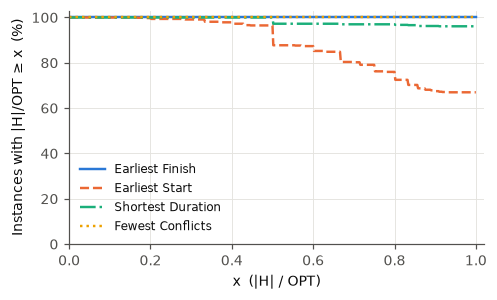

In [6]:
fig, ax = plt.subplots(figsize=(4.6, 2.8))
xs = np.linspace(0, 1, 501)
for h in HEURISTICS:
    r = inst[f"{h}_ratio"].values
    share = [(r >= x).mean() * 100 for x in xs]
    ax.plot(xs, share, color=COLORS[h], linestyle=LINES[h], label=NAMES[h])
ax.set_xlabel("x  (|H| / OPT)")
ax.set_ylabel("Instances with |H|/OPT ≥ x  (%)")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 103)
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
save(fig, "fig3_ratio_distribution")

### Figure 4: the worst instances

Each row is one job, drawn as a bar from start to finish. The jobs the
heuristic picked are filled in its color, and the optimal solution is marked
with a dark outline. These show what misleads each heuristic. Heuristics whose
worst instance is still optimal are skipped.

saved figures/fig4_worst_instances.pdf and .png


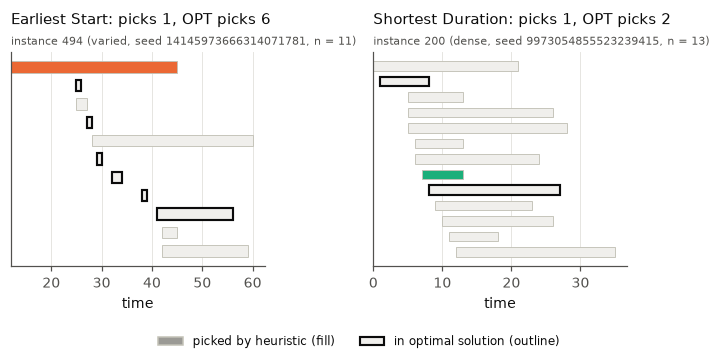

In [7]:
JOB = re.compile(r"(\d+)\[(-?\d+),(-?\d+)\)")

def parse_worst(path):
    out, cur = {}, None
    for line in path.read_text().splitlines():
        m = re.match(r"^(.+): \|H\|/OPT = (\d+)/(\d+)", line)
        if m:
            cur = {"name": m[1], "h": int(m[2]), "opt": int(m[3])}
            out[m[1]] = cur
            continue
        if cur is None:
            continue
        s = line.strip()
        if s.startswith("instance"):
            cur["label"] = s
        elif s.startswith("jobs:"):
            cur["jobs"] = [tuple(map(int, j)) for j in JOB.findall(s)]
        elif s.startswith("opt "):
            cur["opt_ids"] = {int(j[0]) for j in JOB.findall(s)}
        elif s:
            cur["h_ids"] = {int(j[0]) for j in JOB.findall(s)}
    return out

worst = parse_worst(RESULTS / "part5_worst.txt")
by_col = {h: worst[NAMES[h].lower()] for h in HEURISTICS}
shown = [h for h in HEURISTICS if by_col[h]["h"] < by_col[h]["opt"]]

fig, axes = plt.subplots(1, len(shown), figsize=(3.3 * len(shown), 3.0), squeeze=False)
for ax, h in zip(axes[0], shown):
    w = by_col[h]
    jobs = sorted(w["jobs"], key=lambda j: (j[1], j[2]))
    for row, (jid, s, f) in enumerate(jobs):
        picked, optimal = jid in w["h_ids"], jid in w["opt_ids"]
        ax.barh(row, f - s, left=s, height=0.62,
                color=COLORS[h] if picked else "#f0efec",
                edgecolor=INK if optimal else "#c3c2b7",
                linewidth=1.4 if optimal else 0.6)
    ax.invert_yaxis()
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("time")
    ax.set_title(f"{NAMES[h]}: picks {w['h']}, OPT picks {w['opt']}\n", loc="left")
    ax.text(0, 1.02, w["label"], transform=ax.transAxes, fontsize=7, color=INK_2, va="bottom")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor="#9b9a95", edgecolor="#c3c2b7", label="picked by heuristic (fill)"),
                    Patch(facecolor="#f0efec", edgecolor=INK, linewidth=1.4, label="in optimal solution (outline)")],
           loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
save(fig, "fig4_worst_instances")

## Part 6: running time of the greedy algorithms

In [8]:
t = pd.read_csv(RESULTS / "part6_timing.csv")
timed_fams = [f for f in FAMILIES if f in set(t.family)]
wide = t.pivot_table(index=["family", "n"], columns="algorithm", values="median_sec")
(wide[HEURISTICS + ["sort_finish", "sort_start", "sort_duration"]] * 1e3).round(4)  # milliseconds

algorithm          eft      est        sd          fc  sort_finish  \
family n                                                             
dense  100      0.0016   0.0017    0.0017      0.0111       0.0015   
       1000     0.0237   0.0232    0.0243      1.2820       0.0227   
       10000    0.5269   0.5148    0.5530    130.9619       0.5078   
       100000   7.0984   6.9605    7.4074  10694.3040       6.7350   
sparse 100      0.0023   0.0026    0.0033      0.0218       0.0015   
       1000     0.0375   0.0392    0.0687      2.8030       0.0221   
       10000    0.8873   0.8093    2.7795    307.5459       0.4870   
       100000  11.5099  10.4971  260.5920  56365.8562       6.5495   

algorithm      sort_start  sort_duration  
family n                                  
dense  100         0.0016         0.0016  
       1000        0.0227         0.0220  
       10000       0.5101         0.5101  
       100000      6.7450         7.1155  
sparse 100         0.0015         0.0016  
       1000        0.0219         0.0239  
       10000       0.5015         0.5398  
       100000      6.6105         7.1070

### Figure 5: running time against n (log–log)

The dashed gray guides have the slope of n log n and n², pinned to Earliest
Finish and Fewest Conflicts at n = 100. A curve parallel to a guide grows at
that rate. Error bars show the min and max over the runs.

saved figures/fig5_runtime_loglog.pdf and .png


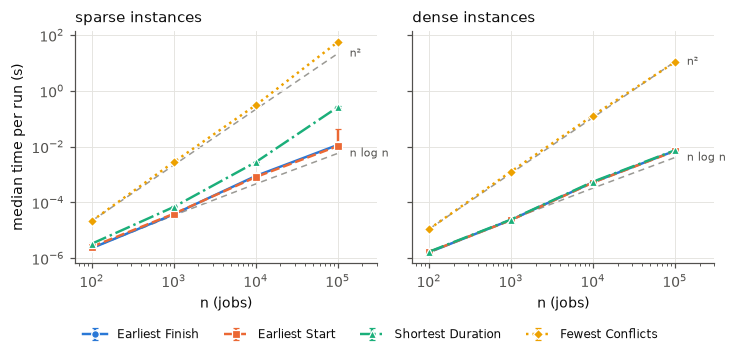

In [9]:
fig, axes = plt.subplots(1, len(timed_fams), figsize=(3.4 * len(timed_fams), 3.0),
                         sharey=True, squeeze=False)
for ax, fam in zip(axes[0], timed_fams):
    d = t[t.family == fam]
    for h in HEURISTICS:
        r = d[d.algorithm == h].sort_values("n")
        ax.errorbar(r.n, r.median_sec,
                    yerr=[r.median_sec - r.min_sec, r.max_sec - r.median_sec],
                    color=COLORS[h], linestyle=LINES[h], marker=MARKERS[h],
                    markeredgecolor="white", markeredgewidth=0.8, capsize=2, label=NAMES[h])
    ns = np.array(sorted(d.n.unique()), dtype=float)
    base = lambda a: d[(d.algorithm == a) & (d.n == ns[0])].median_sec.iloc[0]
    for f, a, lbl in [(lambda n: n * np.log2(n), "eft", "n log n"), (lambda n: n ** 2, "fc", "n²")]:
        guide = base(a) * f(ns) / f(ns[0])
        ax.plot(ns, guide, color="#9b9a95", linestyle=(0, (4, 3)), linewidth=1, zorder=0)
        ax.text(ns[-1] * 1.4, guide[-1], lbl, fontsize=7.5, color=INK_2, va="center")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(ns[0] / 1.6, ns[-1] * 3)
    ax.set_xlabel("n (jobs)")
    ax.set_title(f"{fam} instances", loc="left")
axes[0][0].set_ylabel("median time per run (s)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
save(fig, "fig5_runtime_loglog")

### Figure 6: time per job, divided by log₂ n

For an O(n log n) algorithm this should stay roughly flat as n grows. A curve
that keeps rising grows faster. Fewest Conflicts is left out because its values
are much larger and would flatten the other curves (see Figure 5). The step up
between n = 1,000 and 10,000 is probably a cache effect: the inputs stop
fitting in the faster CPU caches. It is not part of the asymptotic growth.

saved figures/fig6_normalized_runtime.pdf and .png


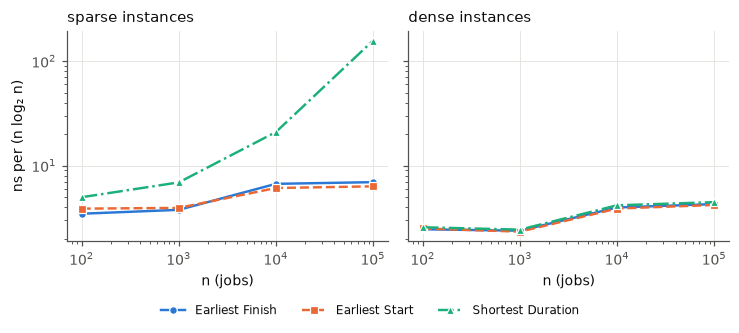

In [10]:
fig, axes = plt.subplots(1, len(timed_fams), figsize=(3.4 * len(timed_fams), 2.8),
                         sharey=True, squeeze=False)
for ax, fam in zip(axes[0], timed_fams):
    d = t[t.family == fam]
    for h in ["eft", "est", "sd"]:
        r = d[d.algorithm == h].sort_values("n")
        ax.plot(r.n, 1e9 * r.median_sec / (r.n * np.log2(r.n)), color=COLORS[h],
                linestyle=LINES[h], marker=MARKERS[h], markeredgecolor="white",
                markeredgewidth=0.8, label=NAMES[h])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("n (jobs)")
    ax.set_title(f"{fam} instances", loc="left")
axes[0][0].set_ylabel("ns per (n log₂ n)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
save(fig, "fig6_normalized_runtime")

### Figure 7: how much of A, B and C's running time is sorting

Median time of the sort alone (copy + qsort, as the algorithm does it),
divided by the algorithm's median total time on inputs of the same family and
n. The two medians come from separate runs, so a value can come out slightly
above 100%.

saved figures/fig7_sort_share.pdf and .png


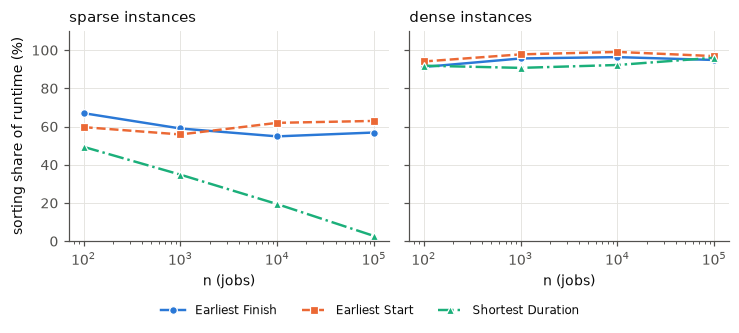

In [11]:
SORT_OF = {"eft": "sort_finish", "est": "sort_start", "sd": "sort_duration"}
fig, axes = plt.subplots(1, len(timed_fams), figsize=(3.4 * len(timed_fams), 2.8),
                         sharey=True, squeeze=False)
for ax, fam in zip(axes[0], timed_fams):
    w = wide.loc[fam]
    for h, s in SORT_OF.items():
        ax.plot(w.index, 100 * w[s] / w[h], color=COLORS[h], linestyle=LINES[h],
                marker=MARKERS[h], markeredgecolor="white", markeredgewidth=0.8,
                label=NAMES[h])
    ax.set_xscale("log")
    ax.set_ylim(0, 110)
    ax.set_xlabel("n (jobs)")
    ax.set_title(f"{fam} instances", loc="left")
axes[0][0].set_ylabel("sorting share of runtime (%)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
save(fig, "fig7_sort_share")

### Growth factor per 10× increase in n

For comparison with the theory: O(n log n) predicts a factor of about 11.5–13
per 10× step at these sizes (for example 10⁵·log 10⁵ / 10⁴·log 10⁴ = 12.5), and
O(n²) predicts 100.

In [12]:
growth = (wide[HEURISTICS].groupby(level="family").pct_change() + 1).dropna(how="all").round(1)
growth

algorithm       eft   est    sd     fc
family n                              
dense  1000    14.5  14.0  14.2  115.9
       10000   22.2  22.2  22.8  102.2
       100000  13.5  13.5  13.4   81.7
sparse 1000    16.3  15.2  20.8  128.7
       10000   23.7  20.7  40.4  109.7
       100000  13.0  13.0  93.8  183.3